# 02 — Modelo 1: clusterização dos animes (personas)

Um usuário novo não tem histórico (*cold start*), então precisamos perguntar do que ele gosta.
Em vez de mostrar milhares de animes, o K-means agrupa os animes parecidos e cada grupo vira uma **persona**, representada pelo seu anime mais popular.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from joblib import dump
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier, export_text

from src.auxiliares import baixar_capa
from src.config import (
    ANIMES_CLUSTERS,
    ANIMES_FEATURES,
    ANIMES_TRATADOS,
    MODELO_KMEANS,
    N_CLUSTERS,
    PASTA_CAPAS,
    PASTA_IMAGENS,
    RANDOM_STATE,
)
from src.graficos import AZUL, CINZA, barras_horizontais, configurar_estilo

configurar_estilo()

animes = pd.read_parquet(ANIMES_TRATADOS)
features = pd.read_parquet(ANIMES_FEATURES)

## 1. Normalização

O K-means usa distância, então todas as variáveis precisam estar na mesma escala.
As *dummies* já são 0 ou 1; o `MinMaxScaler` coloca a `Popularity` nesse mesmo intervalo.

In [2]:
X = MinMaxScaler().fit_transform(features)

## 2. Quantos clusters?

A monografia usa 20 clusters, escolhidos por teste. Aqui conferimos com duas medidas:

- **inércia** (soma das distâncias ao centro do cluster): sempre cai com mais clusters, o que interessa é onde a queda perde força;
- **silhueta** (de -1 a 1): quão bem separado cada anime está dos outros clusters.

,k,Inércia,Silhueta
0,5,36508.515,0.061
1,10,33381.646,0.062
2,15,31526.780,0.062
3,20,30220.227,0.056
4,25,29362.080,0.062
5,30,28556.190,0.067
6,35,27884.669,0.066
7,40,27372.261,0.062


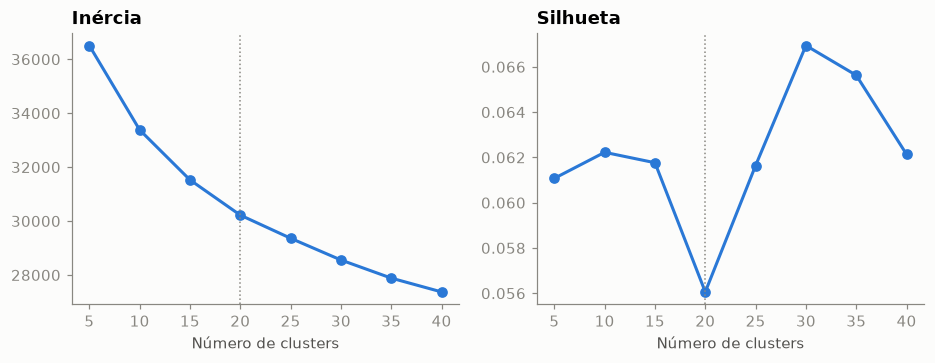

In [3]:
ks = range(5, 45, 5)
inercias, silhuetas = [], []
for k in ks:
    modelo = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inercias.append(modelo.inertia_)
    silhuetas.append(silhouette_score(X, modelo.labels_))

fig, eixos = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, valores, titulo in zip(eixos, [inercias, silhuetas], ["Inércia", "Silhueta"]):
    ax.plot(ks, valores, color=AZUL, linewidth=2, marker="o")
    ax.axvline(N_CLUSTERS, color=CINZA, linestyle=":", linewidth=1)
    ax.set_title(titulo)
    ax.set_xlabel("Número de clusters")
fig.savefig(PASTA_IMAGENS / "escolha_k.png", bbox_inches="tight")

pd.DataFrame({"k": ks, "Inércia": inercias, "Silhueta": silhuetas}).round(3)

Os dados não apontam um número "certo": a inércia cai sem um cotovelo claro e a silhueta fica baixa e praticamente igual (≈0,06) de 5 a 40 clusters.
Com quase 100 variáveis *dummy*, os animes não formam grupos bem separados.

Então o 20 é uma escolha prática, como na monografia: é uma quantidade de opções que dá diversidade sem cansar o usuário na hora de escolher.

## 3. K-means com 20 clusters

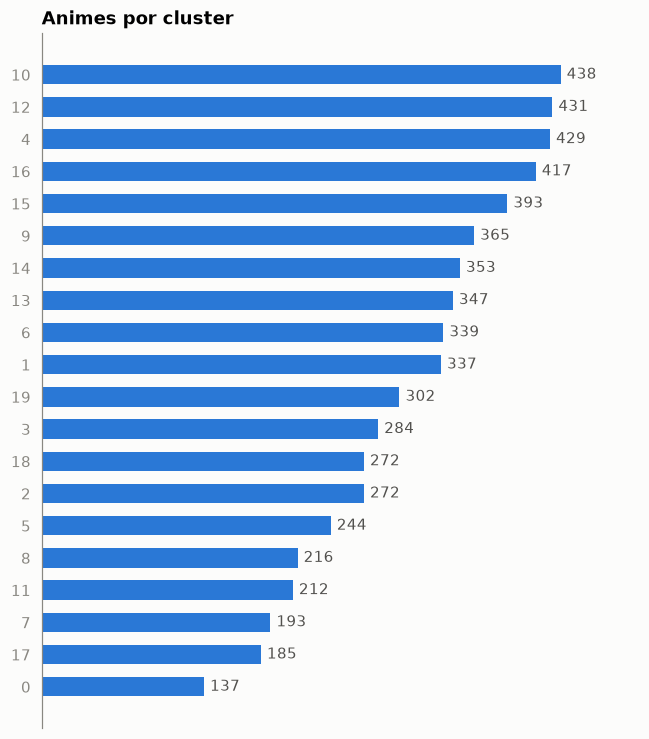

In [4]:
modelo = make_pipeline(
    MinMaxScaler(), KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=RANDOM_STATE)
).fit(features)
animes["Cluster"] = modelo.predict(features)

barras_horizontais(animes["Cluster"].value_counts(), "Animes por cluster", arquivo="tamanho_clusters.png");

### Visualização com PCA

O PCA resume as 96 variáveis em 2 eixos só para conseguirmos desenhar. Os números marcam o centro de cada cluster.

Variância explicada pelos 2 componentes: 15.5%


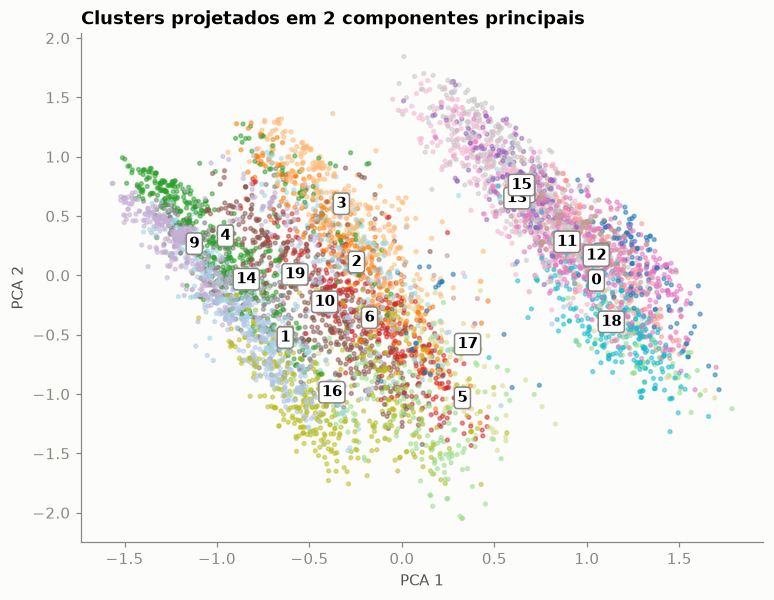

In [5]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
animes[["PCA 1", "PCA 2"]] = pca.fit_transform(X)
print(f"Variância explicada pelos 2 componentes: {pca.explained_variance_ratio_.sum():.1%}")

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(animes["PCA 1"], animes["PCA 2"], c=animes["Cluster"], cmap="tab20", s=6, alpha=0.5)
for cluster, centro in animes.groupby("Cluster")[["PCA 1", "PCA 2"]].mean().iterrows():
    ax.annotate(cluster, centro, ha="center", va="center", fontweight="bold",
                bbox={"boxstyle": "round,pad=0.2", "facecolor": "white", "edgecolor": CINZA})
ax.set_title("Clusters projetados em 2 componentes principais")
ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
fig.savefig(PASTA_IMAGENS / "clusters_pca.png", bbox_inches="tight")

## 4. Personas

O representante de cada cluster é o anime **mais popular**, não o mais central:
o usuário precisa reconhecer o anime para conseguir dizer se gosta.

Para descrever cada persona, pegamos as características que mais se destacam no cluster em relação à média geral.

In [6]:
centros = pd.DataFrame(X, columns=features.columns).groupby(animes["Cluster"]).mean()
destaque = (centros - X.mean(axis=0)).drop(columns="Popularity")
descricoes = destaque.apply(
    lambda linha: " · ".join(dict.fromkeys(c.split(": ")[1] for c in linha.nlargest(4).index)), axis=1
)

animes["Descrição do cluster"] = animes["Cluster"].map(descricoes)
animes["Persona"] = animes.index.isin(animes.groupby("Cluster")["Popularity"].idxmin())

personas = animes.loc[animes["Persona"], ["Cluster", "Name", "Popularity", "Descrição do cluster"]]
personas = personas.sort_values("Cluster").set_index("Cluster")
personas["Animes"] = animes["Cluster"].value_counts()
personas

,Name,Popularity,Descrição do cluster,Animes
Cluster,,,,
0,Pokemon,277,PG - Children · Kids · Fantasy · Adventure,137
1,Kono Subarashii Sekai ni Shukufuku wo!,34,2015-2030 · 2-13 episódios · TV · PG-13 - Teen...,337
2,Shingeki no Kyojin: Kuinaki Sentaku,430,OVA · 2-13 episódios · Manga · Shounen,272
3,Angel Beats! Specials,635,Special · 2-13 episódios · Comedy · 2010-2015,284
4,No Game No Life,10,2010-2015 · 2-13 episódios · TV · PG-13 - Teen...,429
5,Code Geass: Hangyaku no Lelouch,15,Mecha · Sci-Fi · Original · Action,244
6,Fullmetal Alchemist: Brotherhood,3,27+ episódios · TV · Até 2000 · Shounen,339
7,Mononoke Hime,91,Movie · Adventure · 1 episódio · Até 2000,193
8,Boku no Hero Academia the Movie 1: Futari no Hero,310,Shounen · 1 episódio · Manga · PG-13 - Teens 1...,216


### Capas das personas

Para o app ficar visual, baixamos a capa de cada persona da sua página no MyAnimeList. Só baixa o que ainda não está na pasta.

In [7]:
PASTA_CAPAS.mkdir(exist_ok=True)
for mal_id in animes.loc[animes["Persona"], "MAL_ID"]:
    baixar_capa(mal_id, PASTA_CAPAS)

print(len(list(PASTA_CAPAS.glob("*.jpg"))), "capas")

20 capas


## 5. O que o K-means usou para separar?

O K-means não explica suas decisões. Para interpretar, treinamos uma árvore de decisão que tenta **adivinhar o cluster** a partir das variáveis:
as variáveis mais importantes para a árvore são as que mais separam os clusters.

A árvore acerta o cluster de 71% dos animes


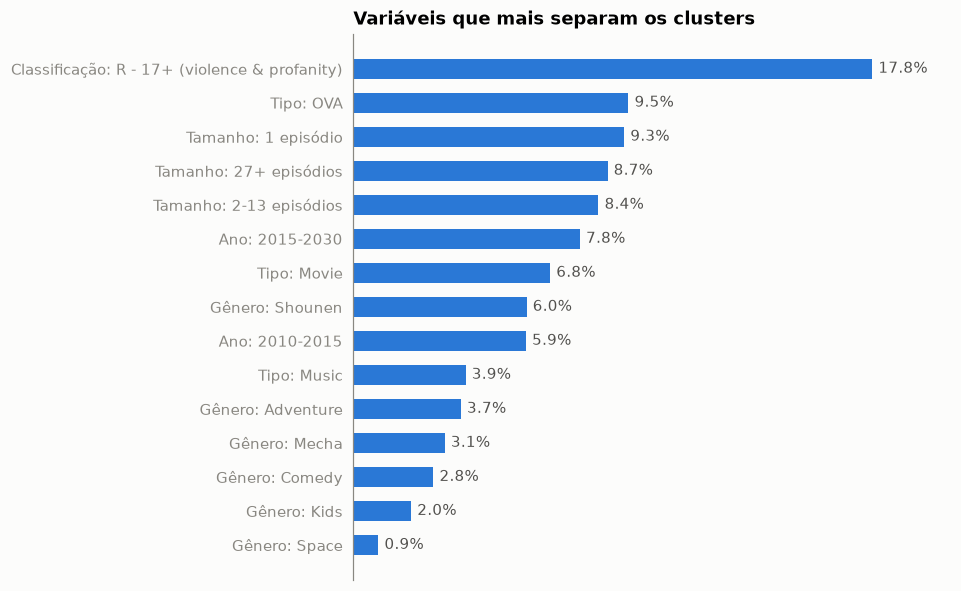

In [8]:
arvore = DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE).fit(features, animes["Cluster"])
print(f"A árvore acerta o cluster de {arvore.score(features, animes['Cluster']):.0%} dos animes")

importancias = pd.Series(arvore.feature_importances_, index=features.columns)
barras_horizontais(importancias.nlargest(15), "Variáveis que mais separam os clusters", formato="{:.1%}", arquivo="importancia_variaveis.png");

In [9]:
print(export_text(arvore, feature_names=list(features.columns), max_depth=2))

|--- Tamanho: 1 episódio <= 0.50
|   |--- Tamanho: 27+ episódios <= 0.50
|   |   |--- Tamanho: 2-13 episódios <= 0.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- Tamanho: 2-13 episódios >  0.50
|   |   |   |--- truncated branch of depth 4
|   |--- Tamanho: 27+ episódios >  0.50
|   |   |--- Gênero: Space <= 0.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- Gênero: Space >  0.50
|   |   |   |--- truncated branch of depth 4
|--- Tamanho: 1 episódio >  0.50
|   |--- Tipo: OVA <= 0.50
|   |   |--- Tipo: Movie <= 0.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- Tipo: Movie >  0.50
|   |   |   |--- truncated branch of depth 4
|   |--- Tipo: OVA >  0.50
|   |   |--- Classificação: R - 17+ (violence & profanity) <= 0.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- Classificação: R - 17+ (violence & profanity) >  0.50
|   |   |   |--- truncated branch of depth 4



Assim como na monografia, o K-means separa primeiro pelas características mais gerais e só depois pelos gêneros:

- **formato** vem primeiro: tamanho (1 episódio, 2-13, 27+) e tipo (OVA, Movie, Music) somam quase metade da importância;
- depois a **classificação etária** (R - 17+) e a **faixa de ano** (2010-2015, 2015-2030);
- os **gêneros** (Shounen, Adventure, Mecha, Comedy, Kids) refinam os grupos;
- **estúdio**, **fonte** e **popularidade** quase não pesam. Manter só uma variável de popularidade tirou o viés que a monografia relata.

Um efeito colateral aparece na tabela de personas: como o formato pesa muito, existem clusters de OVAs e especiais,
e o representante deles é um derivado de uma série famosa (por exemplo *Angel Beats! Specials*, ao lado de *Angel Beats!*).

## 6. Salvando

In [10]:
animes.to_parquet(ANIMES_CLUSTERS, index=False)
dump(modelo, MODELO_KMEANS);